# **Customer Segmentation:** 
## **Who are my customers and much are they willing to pay?**
  



  

In [45]:
import math
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sbn

### **Initial Situation: the DATA**

In [46]:
# Import:
data = pd.read_csv("Mall_Customers.csv")

# Drop ID:
data = data.drop(labels="CustomerID", axis=1)

data

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
...,...,...,...,...
195,Female,35,120,79
196,Female,45,126,28
197,Male,32,126,74
198,Male,32,137,18


Changing `Genre` to `Gender`.

In [47]:
data = data.rename(columns={"Genre": "Gender", 
                     "Age": "Age", 
                     "Annual Income ($k)": "Annual Income ($k)", 
                     "Spending Score (1-100)": "Spending Score (1-100)"})

### **Preprocessing**
#### **Investigating data types and distribution**

In [48]:
data.describe(include="all")

,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200,200.000000,200.000000,200.000000
unique,2,NaN,NaN,NaN
top,Female,NaN,NaN,NaN
freq,112,NaN,NaN,NaN
mean,NaN,38.850000,60.560000,50.200000
std,NaN,13.969007,26.264721,25.823522
min,NaN,18.000000,15.000000,1.000000
25%,NaN,28.750000,41.500000,34.750000
50%,NaN,36.000000,61.500000,50.000000
75%,NaN,49.000000,78.000000,73.000000


Count is equal in all over all features, indicating no missing values.

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Annual Income (k$)'}>],
       [<Axes: title={'center': 'Spending Score (1-100)'}>, <Axes: >]],
      dtype=object)

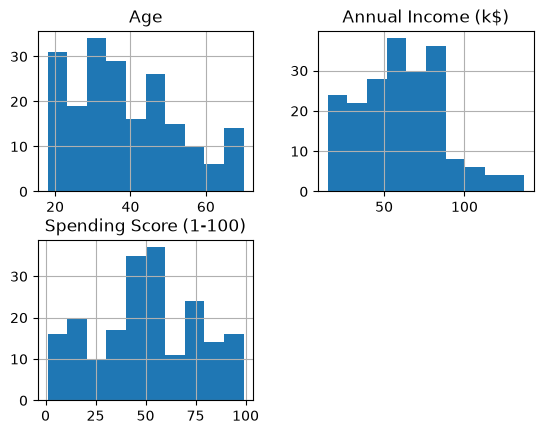

In [49]:
data.hist()

Relatively equal distribution in all numerical features.

<Axes: >

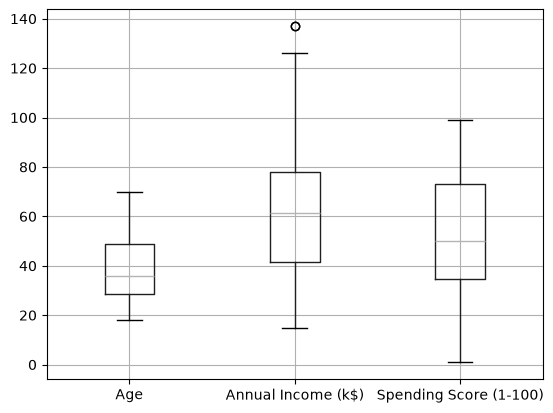

In [50]:
data.boxplot()

Few outliers in `Anual Income`. Investigating further.

In [51]:
q1: float = data["Annual Income (k$)"].quantile(0.25)  # First quartile
q3: float = data["Annual Income (k$)"].quantile(0.75)  # Third quartile
iqr: float = q3 - q1
print(f"Interquartile range: {iqr}")

upper_outliers: pd.Series = data["Annual Income (k$)"] > q3 + iqr * 1.5
print("\nUpper outliers:")
print(data[upper_outliers == True])

Interquartile range: 36.5

Upper outliers:
    Gender  Age  Annual Income (k$)  Spending Score (1-100)
198   Male   32                 137                      18
199   Male   30                 137                      83


Outliers seem neither representative nor decisive. Outliers will be dropped.

In [52]:
if (198 in data.index
    and 199 in data.index):
    data: pd.DataFrame = data.drop([198, 199], axis=0)

print("Outliers dropped:")
data.tail()

Outliers dropped:


,Gender,Age,Annual Income (k$),Spending Score (1-100)
193,Female,38,113,91
194,Female,47,120,16
195,Female,35,120,79
196,Female,45,126,28
197,Male,32,126,74


### **Converting data to all numeric values**

In [55]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

transformer = ColumnTransformer(
    [
        ("Gender transformed", OneHotEncoder(categories="auto", dtype=int, sparse_output=False), ["Gender"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
    )
transformer.set_output(transform="pandas")

num_data: pd.DataFrame = transformer.fit_transform(data)

print("Transformed data:")
num_data

Transformed data:


,Gender_Female,Gender_Male,Age,Annual Income (k$),Spending Score (1-100)
0,0,1,19,15,39
1,0,1,21,15,81
2,1,0,20,16,6
3,1,0,23,16,77
4,1,0,31,17,40
...,...,...,...,...,...
193,1,0,38,113,91
194,1,0,47,120,16
195,1,0,35,120,79
196,1,0,45,126,28


### **Analysis**
#### **Analysing correlation between data**
##### **Correlation matrix**

<Axes: >

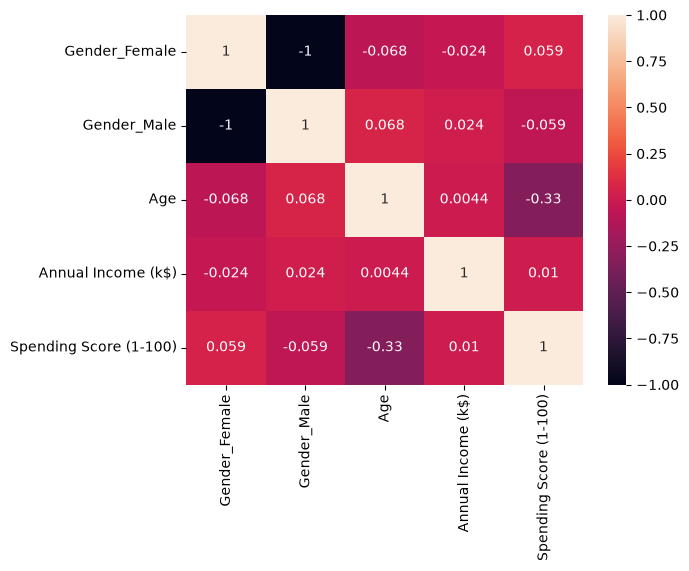

In [57]:
correlation_matrix = num_data.corr()
sbn.heatmap(data=correlation_matrix, annot=True)

##### **Scatter plots**

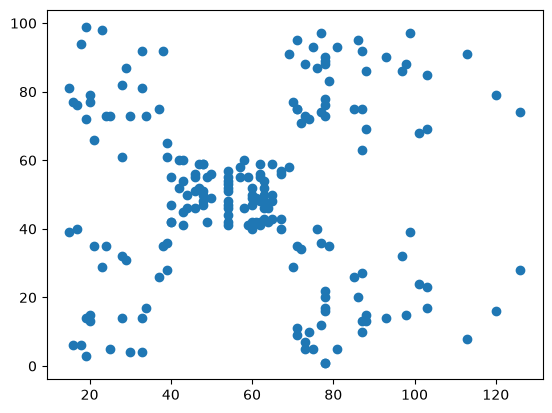

In [ ]:
# Annual income and spending score
plt.scatter(x=data["Annual Income (k$)"],
            y=data["Spending Score (1-100)"])